# Description

In this notebook we prepare the simulation data of Li-ion battery under varying current load. Unstable simulations are not saved.

# Import

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
from progpy.models import BatteryElectroChem
import sys
sys.path.append('../')
# from config import battery_varying_load_params as params
params = {
    "path": "testwdir/batsim"
}

from copy import deepcopy
from functools import partial

import warnings
warnings.filterwarnings(action='error', category=RuntimeWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)

number_of_trajectories = 100

# Simulate

In [2]:
def update(ps):
    """
    Updates the battery model with the new parameters (This will be deprecated when the github repo is updated)
    """
    ps['qMax'] = ps['qMobile']/(ps['xnMax']-ps['xnMin']) # note qMax = qn+qp
    # Volumes (total volume is 2*P.Vol), assume volume at each electrode is the
    # same and the surface/bulk split is the same for both electrodes
    ps['VolS'] = ps['VolSFraction']*ps['Vol'] # surface volume
    ps['VolB'] = ps['Vol'] - ps['VolS'] # bulk volume

    # set up charges (Li ions)
    ps['qpMin'] = ps['qMax']*ps['xpMin'] # min charge at pos electrode
    ps['qpMax'] = ps['qMax']*ps['xpMax'] # max charge at pos electrode
    ps['qpSMin'] = ps['qMax']*ps['xpMin']*ps['VolSFraction'] # min charge at surface, pos electrode
    ps['qpBMin'] = ps['qMax']*ps['xpMin']*(ps['Vol'] - ps['VolS'])/ps['Vol'] # min charge at bulk, pos electrode
    ps['qpSMax'] = ps['qMax']*ps['xpMax']*ps['VolS']/ps['Vol'] # max charge at surface, pos electrode
    ps['qpBMax'] = ps['qMax']*ps['xpMax']*ps['VolB']/ps['Vol'] # max charge at bulk, pos electrode
    ps['qnMin'] = ps['qMax']*ps['xnMin'] # max charge at neg electrode
    ps['qnMax'] = ps['qMax']*ps['xnMax'] # max charge at neg electrode
    ps['qnSMax'] = ps['qMax']*ps['xnMax']*ps['VolSFraction'] # max charge at surface, neg electrode
    ps['qnBMax'] = ps['qMax']*ps['xnMax']*(1-ps['VolSFraction']) # max charge at bulk, neg electrode
    ps['qnSMin'] = ps['qMax']*ps['xnMin']*ps['VolSFraction'] # min charge at surface, neg electrode
    ps['qnBMin'] = ps['qMax']*ps['xnMin']*(1-ps['VolSFraction']) # min charge at bulk, neg electrode
    ps['qSMax'] = ps['qMax']*ps['VolSFraction'] # max charge at surface (pos and neg)
    ps['qBMax'] = ps['qMax']*(1-ps['VolSFraction']) # max charge at bulk (pos and neg)
    ps['x0']['qpS'] = ps['qpSMin']
    ps['x0']['qpB'] = ps['qpBMin']
    ps['x0']['qnS'] = ps['qnSMax']
    ps['x0']['qnB'] = ps['qnBMax']
    ps['x0']['qMax'] = ps['qMobile']
    ps['x0']['Ro'] = ps['Ro']
    return ps

In [3]:
def simulate_battery_EOL(q, R0):
    batt = BatteryElectroChem(process_noise= 0, measurement_noise=0.01)
    
    batt.parameters['qMobile'] = q
    batt.parameters['Ro'] = R0
    batt.parameters=update(deepcopy(batt.parameters))
    sim_config = {'save_freq': 2,
                  'dt': 2,
                  'threshold_keys': ['InsufficientCapacity'],
                  'print': False,
                  'progress': False}
    
    load = 1
    current_state = 'charge'
    step = 0
    rest_step = 0
    next_change = np.random.randint(1, 600)

    def future_loading(t, x=None):
        nonlocal load, current_state, step, next_change, rest_step
        if x is not None:
            event_state = batt.event_state(x)
            if event_state["EOD"] > 0.95:
                if current_state == 'charge':
                    step = 0
                    current_state = 'discharge'
                    next_change = np.random.uniform(1, 1000)
                    load = np.random.uniform(0.5, 3)
                else:
                    step += 1
                    if step >= next_change:
                        step = 0
                        next_change = np.random.uniform(1, 1000)
                        load = np.random.uniform(0.5, 3)
            elif event_state["EOD"] < 0.05:
                if current_state == 'discharge':
                    load = 0
                    current_state = 'rest'
                elif current_state == 'rest':
                    rest_step += 1
            elif current_state == 'rest':
                if rest_step < 30:
                    rest_step += 1
                else:
                    rest_step = 0
                    current_state = 'charge'
                    load = -3
            elif current_state == 'discharge':
                step += 1
                if step >= next_change:
                    step = 0
                    next_change = np.random.uniform(1, 1000)
                    load = np.random.uniform(0.5, 3)
        return batt.InputContainer({'i': load})
    
    simulated_results = batt.simulate_to_threshold(future_loading, **sim_config)
    
    return simulated_results

In [4]:
def single_simulation_run(n):
    q = np.random.uniform(7500, 7600)
    R0 = np.random.uniform(0.117215-0.01, 0.117215+0.01)
    times, inputs, states, outputs, event_states = simulate_battery_EOL(q, R0)
    
    df = pd.DataFrame()
    df['time'] = times
    df['inputs'] = [x['i'] for x in inputs]
    df['q'] = [x['qMax'] for x in states]
    df['R0'] = [x['Ro'] for x in states]
    df['D'] = [x['D'] for x in states]
    df['temperature'] = [x['t'] for x in outputs]
    df['v'] = [x['v'] for x in outputs]
    return df

In [5]:
from pathlib import Path


n = 1

while n < number_of_trajectories:
    # try:
    data = single_simulation_run(n)
    Path(params["path"]).mkdir(parents=True, exist_ok=True)
    data.to_feather(f'{params["path"]}/{n}.feather')
    print(n)
    n += 1
    
    break

1


array([<Axes: xlabel='time'>, <Axes: xlabel='time'>,
       <Axes: xlabel='time'>, <Axes: xlabel='time'>,
       <Axes: xlabel='time'>, <Axes: xlabel='time'>], dtype=object)

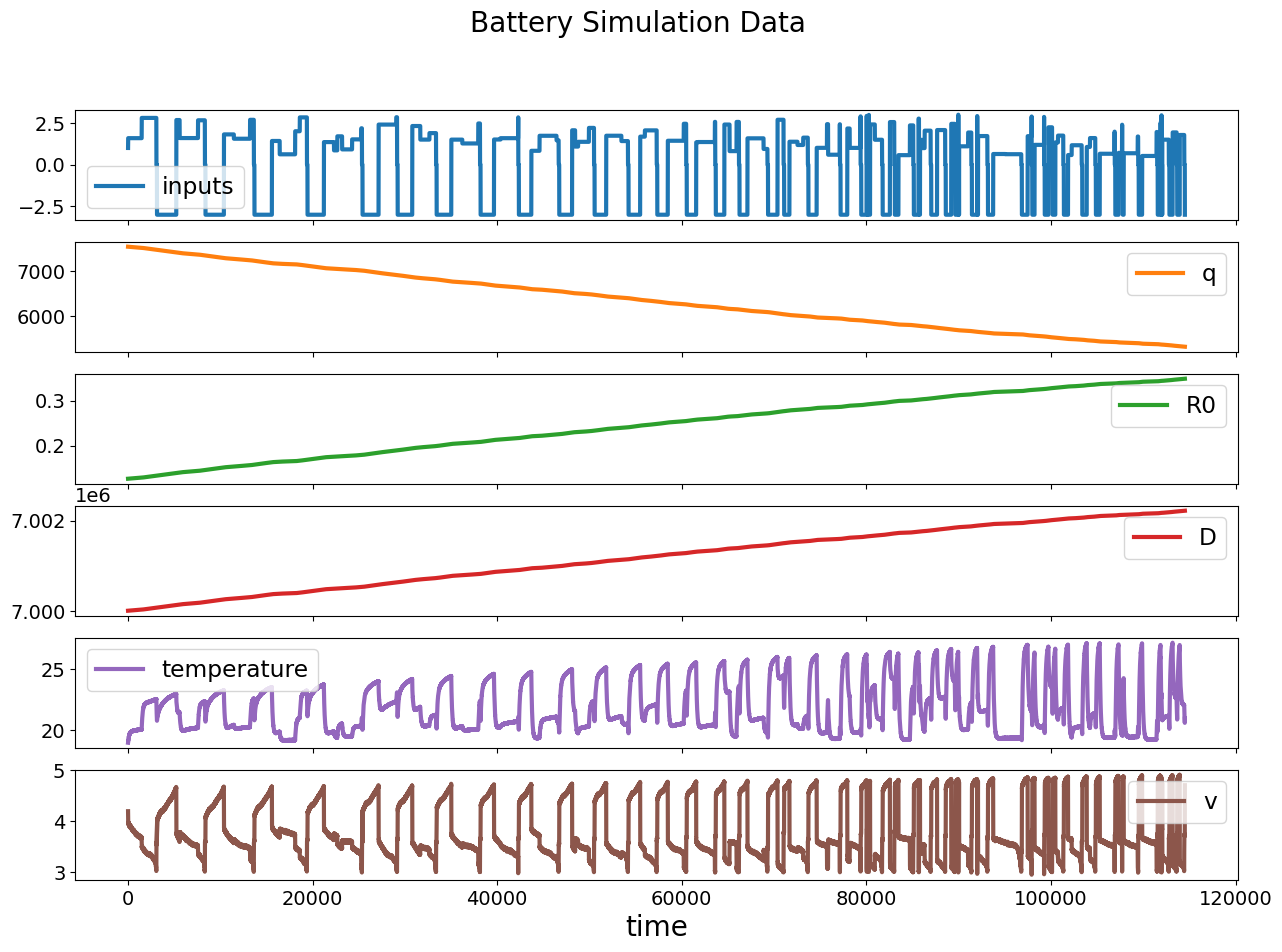

In [9]:
import pandas as pd

data = pd.read_feather(f'{params["path"]}/{1}.feather')

data.plot(x='time', subplots=True, figsize=(15, 10), title='Battery Simulation Data')

In [10]:
data.to_csv('/home/levtel/projects/TabPHM/datasets/battery/first.csv')



In [12]:
pd.read_csv('/home/levtel/projects/TabPHM/datasets/battery/first.csv', index_col=0)

,time,inputs,q,R0,D,temperature,v
0,0.0,1.000000,7539.256392,0.126454,7.000000e+06,18.946272,4.189272
1,2.0,1.587794,7539.224636,0.126457,7.000000e+06,18.954314,4.115596
2,4.0,1.587794,7539.192880,0.126460,7.000000e+06,18.965867,4.060824
3,6.0,1.587794,7539.161124,0.126463,7.000000e+06,18.979519,4.028456
4,8.0,1.587794,7539.129368,0.126466,7.000000e+06,18.979161,4.007294
...,...,...,...,...,...,...,...
57252,114504.0,-3.000000,5320.225619,0.348357,7.002219e+06,20.590336,4.302109
57253,114506.0,-3.000000,5320.165619,0.348363,7.002219e+06,20.646904,4.471495
57254,114508.0,-3.000000,5320.105619,0.348369,7.002219e+06,20.715044,4.573060
57255,114510.0,-3.000000,5320.045619,0.348375,7.002219e+06,20.818057,4.650264


In [14]:
sum(data['inputs']>0)

37489